# 🌊 Predicting Significant Wave Heights for Ocean Exploration (70/100)


Welcome to MSC-AI Consulting! You are leading a consulting team in an important project with a top client, the Global Ocean Exploration Initiative (GOEI). This client focuses on understanding the dynamic nature of oceanic waves and their potential impact on marine operations.


## 📄 Client’s Brief
GOEI has provided you with a dataset that records oceanic and environmental conditions, and they would like you to predict significant wave heights (`Hsig`) based on these conditions. Accurate wave height predictions are crucial for planning maritime operations and ensuring safety.


## Understanding the Data

The data provided in `Hs.csv` includes several features that capture environmental and oceanic conditions related to wave height. Here are the key columns in the dataset:

- `Hsig`: Significant wave height, measured in meters, which serves as the target variable for your regression model. Predicting this feature accurately is essential for understanding ocean conditions.
- `Temperature`: Represents the water temperature, which can be analyzed in its continuous form or transformed into categories (e.g., Low, Moderate, High) to capture potential temperature bands.
- `Wind Speed`: The speed of the wind measured in meters per second (m/s). Wind speed is a critical factor that influences wave heights and ocean conditions.
- `Wave Direction (Dir)`: The direction from which the waves are approaching, measured in degrees (0° - 360°). This feature can help reveal patterns associated with wave height depending on the wave’s origin.
- `Depth`: The depth of the water at the measurement location, measured in meters. Depth provides context for interpreting oceanic conditions at different levels below the surface.
- `X-Windv` and `Y-Windv`: Components of wind velocity along the x-axis and y-axis, which capture directional wind forces.
- `Season`: Represents the seasonal classification (e.g., Winter, Spring, Summer, Fall) for each measurement, allowing you to capture potential seasonal effects on wave heights.
- `Wind_Dir_Category`: A categorical version of Wave Direction, grouped into broader directional categories (e.g., North, East, South, West) for simplified analysis of directional effects on wave height.

# Part 1: Data Preprocessing

## Objective
Your primary goal is to predict Hsig (significant wave height).

## Train-Test Split
Begin by splitting the dataset into 70% for training and 30% for testing. Given the structure of this project, there’s no need for a separate validation set, as GOEI wants you to maximize training data usage through cross-validation.

## Data Preprocessing
- Use insights from your EDA to inform preprocessing steps. While specific steps are up to you, standard preprocessing tasks should be implemented.
- The client has confirmed that no outliers are present in the dataset, so outlier handling is unnecessary.

## Feature Engineering and Selection
In addition to all standard steps (e.g., addressing collinearity and encoding categorical variables), GOEI encourages you to explore potential feature transformations that could improve predictive performance. such as Binning and/or interaction terms.

**Name your final preprocessing pipeline as `prep_pipe`.**
  

# Part 2: Model Selection and Evaluation

With your data preprocessed and features prepared, GOEI requests a structured approach to model selection and evaluation. Follow these steps:

- Baseline Model: Start by fitting a parametric linear model as a baseline. Evaluate this model using both R² and Mean Squared Error (MSE) as performance metrics. These metrics will serve as a reference to assess improvements with other models.

- Ensemble Models: GOEI is interested in seeing how ensemble methods perform on this dataset. Choose two ensemble models. To tune these models, use `RandomizedSearchCV` with 5-fold cross-validation (`cv=5`) and explore **two different hyperparameters for each model**

- Performance Evaluation: For each model, evaluate performance on R² and MSE. Based on the results, choose the best-performing model and save it as `final_model`. Record the best hyperparameters used in this model as `Best_parameters`.

- Test Set Evaluation: Use the `final_model` to predict on the test set and assess performance using R² and MSE. Report these metrics as evidence of the model’s effectiveness on unseen data.

# 📊 GOEI’s Assessment Criteria --  70 points overall

Your work will be evaluated based on the following criteria:

## Pipeline Structure and Implementation: 14 points

Effective and organized implementation of the pipeline, covering both data preprocessing (`prep_pipe`) and modeling steps. A structured and reusable pipeline.

## Data Preprocessing and Feature Engineering (Part 1): 33 points

- Evidence-based data preparation steps informed by EDA insights.
- Thoughtful and relevant feature engineering transformations and interactions that demonstrate innovation and alignment with the problem context.
- Attention to collinearity, data transformations, and the creation of meaningful features that capture underlying data relationships.

## Model Selection, Tuning, and Evaluation (Part 2): 23 points

- Appropriate choice of a baseline model and ensemble models.
- Evidence of hyperparameter tuning using `RandomizedSearchCV` with clear documentation of parameters and cross-validation.
- Thorough performance evaluation on both the training (cross-validation) and test sets using R² and MSE, demonstrating a standard, evidence-based approach in model selection and assessment.


## Documentation

- Use concise markdown explanations (less than a line each) to explain each preprocessing and modeling step, highlighting what you’re doing and why.
- Summarize your final choices and rationale in a short paragraph, emphasizing the evidence that informed each decision.



GOEI values a well-justified approach over specific performance numbers, so focus on following the requirements and showing thoughtful, evidence-based innovation in your work. Remember to set `random_state=42` where needed for reproducibility.

In [43]:
# Add data
import pandas as pd

data = pd.read_csv("data/Hs.csv")
data.head()

,Xp,Yp,Hsig,Dir,Depth,X-Windv,Y-Windv,U10,Season,Temperature,Wind_Speed,Wave_Steepness,Wind_Dir_Category
0,52.57,27.38,0.03444,353.248,35.6057,0.3128,-1.7557,1.06,Summer,14.045279,1.783347,0.023272,West
1,52.57,27.38,0.03459,350.817,35.6057,0.4156,-1.0176,0.40,Summer,13.727790,1.099197,0.022787,West
2,52.57,27.38,0.03479,354.399,35.6057,0.4148,-1.7209,1.26,Summer,14.120766,1.770185,0.025072,West
3,52.57,27.38,0.03502,348.335,35.6057,0.1343,-0.3577,1.39,Fall,14.558437,0.382081,0.022834,West
4,52.57,27.38,0.03545,138.355,35.6057,1.9610,-0.3797,1.06,Summer,13.679845,1.997422,0.016984,East


In [44]:
# Checking for duplicates in dataset
data.duplicated().sum()

3

In [45]:
# Dropping duplicates
data.drop_duplicates(inplace=True)

# Checking for duplicates in dataset
data.duplicated().sum()

0

In [46]:
# Splitting the data into features and target
y = data["Hsig"]
X = data.drop("Hsig", axis=1)

print(X.head())
print("")
print(f"Target Feature: \n{y.head()}")

      Xp     Yp      Dir    Depth  X-Windv  Y-Windv   U10  Season  \
0  52.57  27.38  353.248  35.6057   0.3128  -1.7557  1.06  Summer   
1  52.57  27.38  350.817  35.6057   0.4156  -1.0176  0.40  Summer   
2  52.57  27.38  354.399  35.6057   0.4148  -1.7209  1.26  Summer   
3  52.57  27.38  348.335  35.6057   0.1343  -0.3577  1.39    Fall   
4  52.57  27.38  138.355  35.6057   1.9610  -0.3797  1.06  Summer   

   Temperature  Wind_Speed  Wave_Steepness Wind_Dir_Category  
0    14.045279    1.783347        0.023272              West  
1    13.727790    1.099197        0.022787              West  
2    14.120766    1.770185        0.025072              West  
3    14.558437    0.382081        0.022834              West  
4    13.679845    1.997422        0.016984              East  

Target Feature: 
0    0.03444
1    0.03459
2    0.03479
3    0.03502
4    0.03545
Name: Hsig, dtype: float64


In [47]:
# Splitting the data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
# No further split as validation set is not needed as outlined in the task

In [48]:
# Checking if more than 30% of the data is missing
X_train.isnull().sum() / X_train.shape[0] * 100

Xp                    0.000000
Yp                    0.000000
Dir                   0.000000
Depth                 0.000000
X-Windv               0.000000
Y-Windv               0.029091
U10                  99.237403
Season                0.012468
Temperature           0.012468
Wind_Speed            0.024935
Wave_Steepness        0.016623
Wind_Dir_Category     0.012468
dtype: float64

U10 is mostly NaN values, so this column will be dropped. 
Otherwise the NaN values will be imputed using mean in pipeline

In [49]:
# U10 is mostly null so we will drop it after double checking
print(X_train["U10"])

# Dropping U10
X_train.drop("U10", axis=1, inplace=True)
X_test.drop("U10", axis=1, inplace=True)
X_train.head()

67190   NaN
53616   NaN
42844   NaN
41054   NaN
65293   NaN
         ..
37197   NaN
6268    NaN
54889   NaN
863     NaN
15798   NaN
Name: U10, Length: 48125, dtype: float64


,Xp,Yp,Dir,Depth,X-Windv,Y-Windv,Season,Temperature,Wind_Speed,Wave_Steepness,Wind_Dir_Category
67190,52.57,27.38,348.801,35.6057,4.9390,-6.3596,Summer,14.466337,8.052219,0.224831,West
53616,52.57,27.38,358.303,35.6057,-0.8858,-2.5059,Summer,14.245134,2.657852,0.124806,West
42844,52.57,27.38,351.653,35.6057,4.2810,-2.1436,Summer,14.020267,4.787691,0.133315,West
41054,52.57,27.38,344.927,35.6057,5.5828,-1.2542,Summer,14.057357,5.721947,0.152197,West
65293,52.57,27.38,350.382,35.6057,5.1028,-5.4646,Summer,13.167133,7.476658,0.203409,West


In [50]:
# Identifying the columns that are numerical and categorical
X_train.dtypes

Xp                   float64
Yp                   float64
Dir                  float64
Depth                float64
X-Windv              float64
Y-Windv              float64
Season                object
Temperature          float64
Wind_Speed           float64
Wave_Steepness       float64
Wind_Dir_Category     object
dtype: object

In [51]:
# Identify the numerical column names and categorical column names
num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(include="object").columns

print(f"Numerical Columns: {num_cols}")
print(f"Categorical Columns: {cat_cols}")

Numerical Columns: Index(['Xp', 'Yp', 'Dir', 'Depth', 'X-Windv', 'Y-Windv', 'Temperature',
       'Wind_Speed', 'Wave_Steepness'],
      dtype='object')
Categorical Columns: Index(['Season', 'Wind_Dir_Category'], dtype='object')


In [52]:
print(X_train[num_cols].head())

          Xp     Yp      Dir    Depth  X-Windv  Y-Windv  Temperature  \
67190  52.57  27.38  348.801  35.6057   4.9390  -6.3596    14.466337   
53616  52.57  27.38  358.303  35.6057  -0.8858  -2.5059    14.245134   
42844  52.57  27.38  351.653  35.6057   4.2810  -2.1436    14.020267   
41054  52.57  27.38  344.927  35.6057   5.5828  -1.2542    14.057357   
65293  52.57  27.38  350.382  35.6057   5.1028  -5.4646    13.167133   

       Wind_Speed  Wave_Steepness  
67190    8.052219        0.224831  
53616    2.657852        0.124806  
42844    4.787691        0.133315  
41054    5.721947        0.152197  
65293    7.476658        0.203409  


In [53]:
# Producing statistical summary of the numerical columns
X_train[num_cols].describe()

,Xp,Yp,Dir,Depth,X-Windv,Y-Windv,Temperature,Wind_Speed,Wave_Steepness
count,4.812500e+04,48125.00,48125.000000,4.812500e+04,48125.000000,48111.000000,48119.000000,48113.000000,48117.000000
mean,5.257000e+01,27.38,220.353672,3.560570e+01,1.695938,-1.250506,13.798608,3.884876,0.120883
std,2.842200e-14,0.00,150.766707,1.421100e-14,2.879089,2.823709,0.497437,2.371340,0.051925
min,5.257000e+01,27.38,0.000000,3.560570e+01,-9.087300,-11.874300,11.564120,0.035977,0.015663
25%,5.257000e+01,27.38,63.358000,3.560570e+01,-0.272400,-3.090000,13.460457,2.094586,0.083079
50%,5.257000e+01,27.38,340.038000,3.560570e+01,1.597400,-1.274100,13.802713,3.237759,0.114889
75%,5.257000e+01,27.38,353.493000,3.560570e+01,3.594300,0.665050,14.135796,5.278546,0.150860
max,5.257000e+01,27.38,359.998000,3.560570e+01,12.412800,11.782200,16.036464,13.467091,0.335863


In [54]:
y_train.describe()

count    48125.000000
mean         0.434984
std          0.340381
min          0.034440
25%          0.174560
50%          0.317370
75%          0.608070
max          2.271350
Name: Hsig, dtype: float64

Negative values only present in X-Windv and Y-Windv, which seem plausible as they are velocity vectors. 
Otherwise no negative values to consider.
Task states that there are no outliers in dataset, and as such it will be assumed that this dataset is now valid (still needs to be imputed)

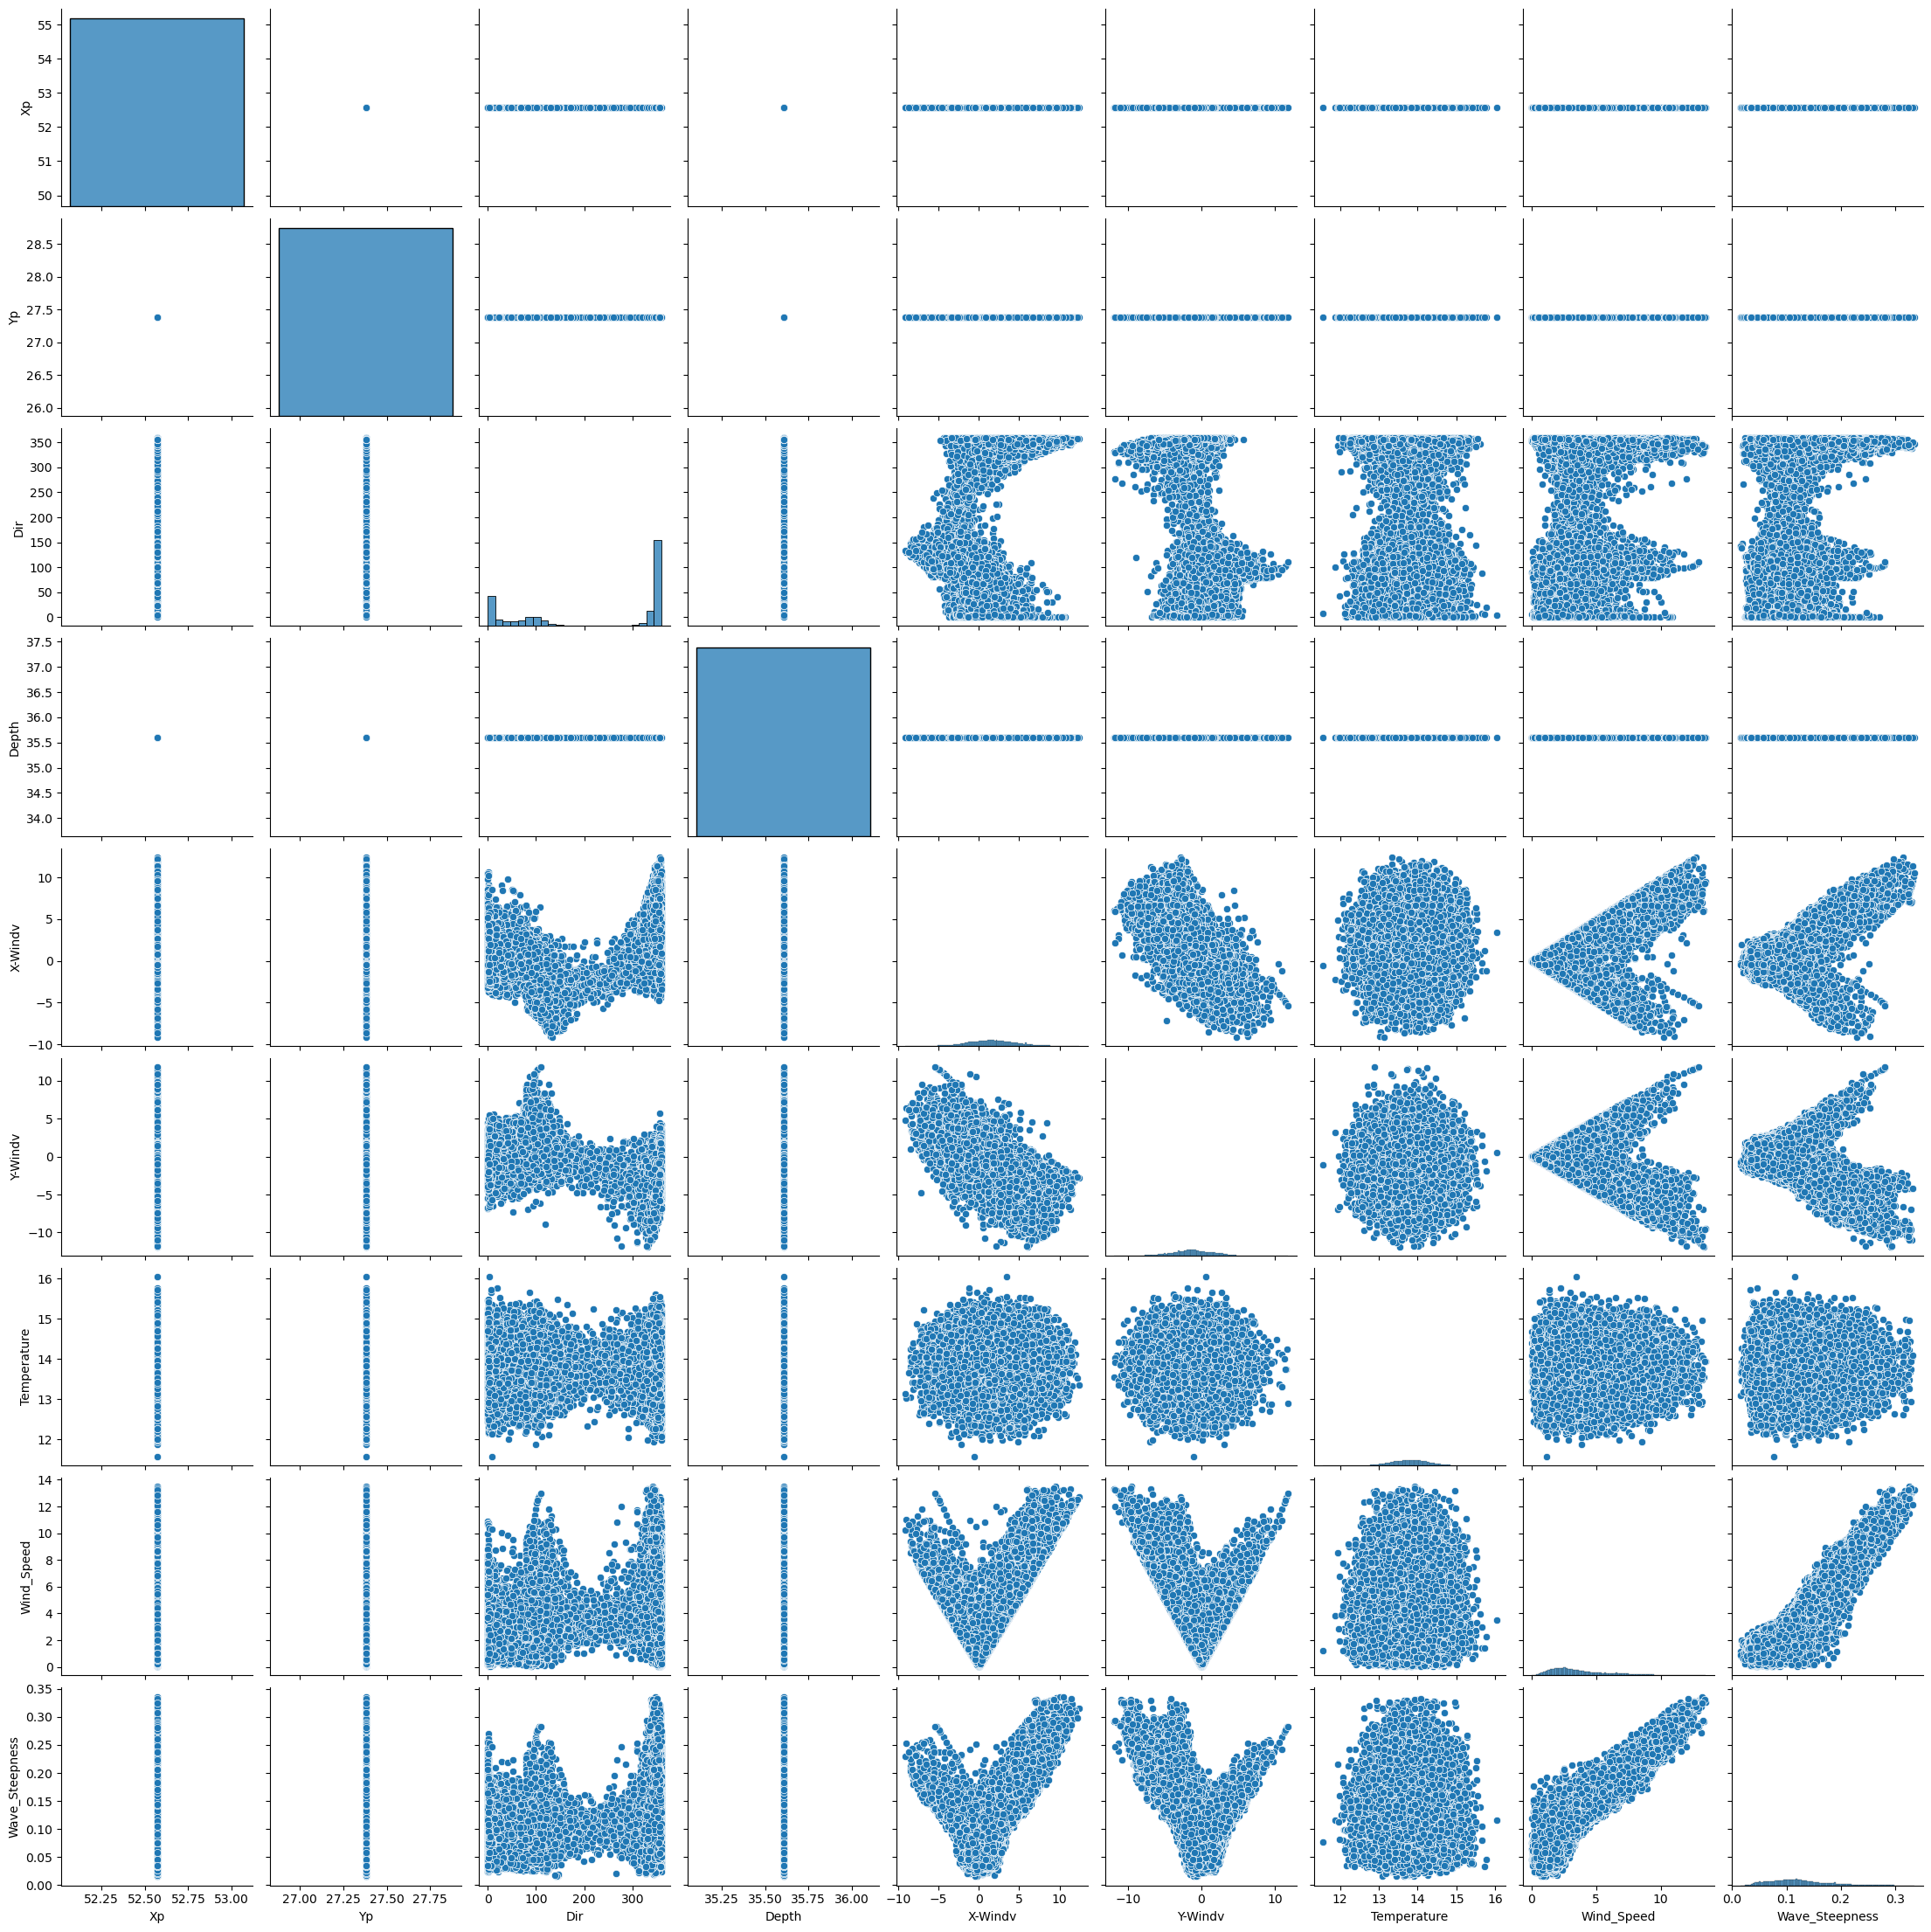

In [55]:
# Producing pairplot for numerical columns
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(X_train[num_cols])

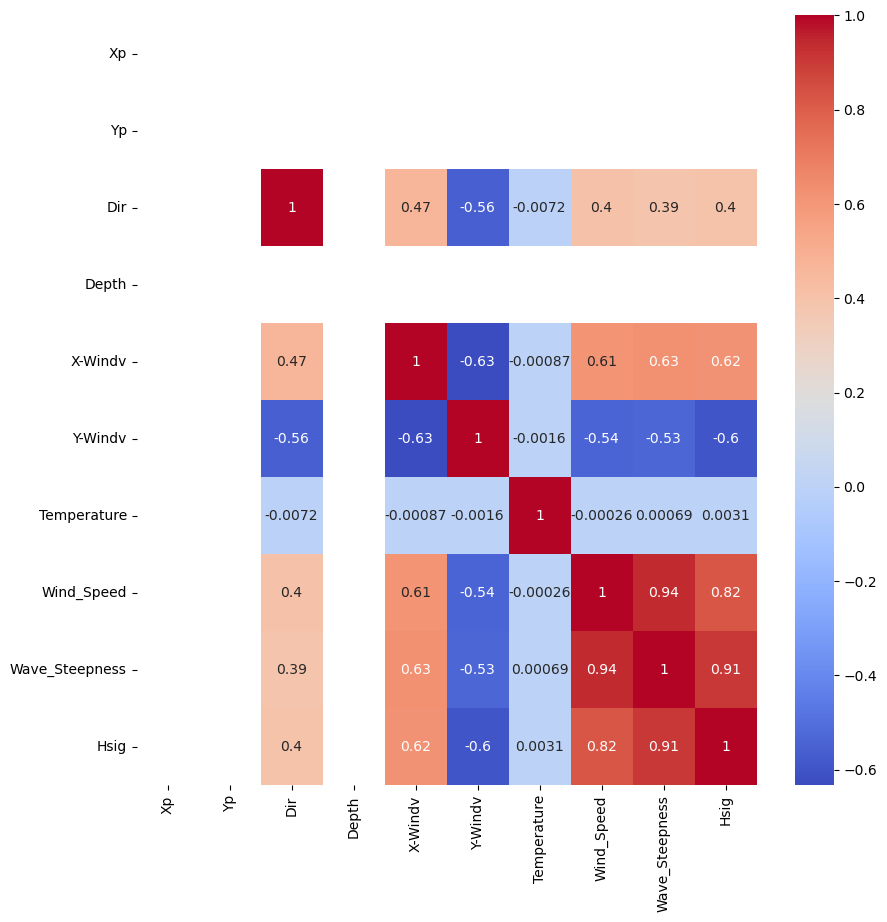

In [56]:
# Checking for colinear features in the numerical columns

# Appending the target feature to the numerical columns
corr_num_cols = num_cols.append(pd.Index(["Hsig"]))

# Visualizing the correlation matrix
plt.figure(figsize=(10, 10))
sns.heatmap(data[corr_num_cols].corr(), annot=True, cmap="coolwarm")
plt.show()

Wave steepness and wind speed both have a high colinearity of 0.94, so one should be omitted. 

Given that wave steepness has a better correlation with the target feature, wind speed will be dropped

Other columns have colinearity of less than 0.75 and are accepted 

In [57]:
# Dropping "Wave_Steepness" as it is highly correlated with "Wind_Speed"
X_train.drop("Wind_Speed", axis=1, inplace=True)
X_test.drop("Wind_Speed", axis=1, inplace=True)

# Dropping Xp, Yp, and Depth as there is not enough of a distribution to make a prediction
X_train.drop(["Xp", "Yp", "Depth"], axis=1, inplace=True)
X_test.drop(["Xp", "Yp", "Depth"], axis=1, inplace=True)

In [58]:
# Updating num_cols
num_cols = X_train.select_dtypes(include="number").columns
num_cols

Index(['Dir', 'X-Windv', 'Y-Windv', 'Temperature', 'Wave_Steepness'], dtype='object')

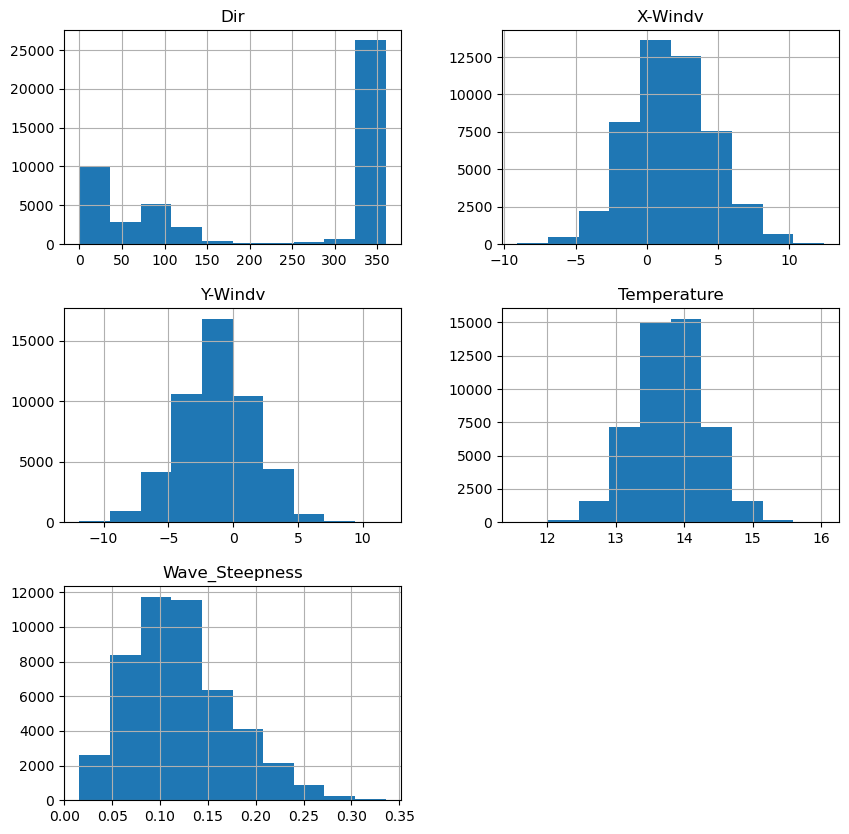

In [59]:
# Producing histograms for numerical columns
X_train[num_cols].hist(figsize=(10, 10))
plt.show()

From this we can see that that X-Windv, Y-Windv and Temperature are normal distributions, and a standard scaler can be used.

Wave_Steepness is a skewed distribution and a min-max scaler can be used.

Dir is non-normal and as it is a direction it is difficult to perform statistics for properly and therefore will be dropped.

In [60]:
# Bin the "Dir" column
X_train["Dir"] = pd.cut(X_train["Dir"], bins=8, labels=["NNE", "NEE", "SEE", "SSE", "SSW", "SWW", "NWW", "NNW"])

X_train 

,Dir,X-Windv,Y-Windv,Season,Temperature,Wave_Steepness,Wind_Dir_Category
67190,NNW,4.9390,-6.3596,Summer,14.466337,0.224831,West
53616,NNW,-0.8858,-2.5059,Summer,14.245134,0.124806,West
42844,NNW,4.2810,-2.1436,Summer,14.020267,0.133315,West
41054,NNW,5.5828,-1.2542,Summer,14.057357,0.152197,West
65293,NNW,5.1028,-5.4646,Summer,13.167133,0.203409,West
...,...,...,...,...,...,...,...
37197,NNW,-0.4958,-0.9013,Summer,13.360990,0.075037,West
6268,SEE,-0.8176,-1.8203,Summer,14.280511,0.075272,East
54889,NNW,3.7002,-5.7697,Summer,14.269467,0.169868,West
863,NNE,-0.4083,-0.3449,Fall,14.694861,0.034525,North


In [61]:
# Updating num_cols
num_cols = X_train.select_dtypes(include="number").columns

# Updating cat_cols
cat_cols = X_train.select_dtypes(include="object").columns

In [62]:
# Creating pipeline to preprocess the data
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler, FunctionTransformer
import numpy as np

### Creating the preprocessing pipeline for numerical columns

# Using standard scaler for X-Windv, Y-Windv, and Temperature
num_transformer_std = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Using minmax scaler for Wind_Speed
num_transformer_minmax = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", MinMaxScaler())
])

num_tranformer = ColumnTransformer(
    transformers=[
        ("std", num_transformer_std, ["X-Windv", "Y-Windv", "Temperature"]),
        ("minmax", num_transformer_minmax, ["Wave_Steepness"])
    ])

# Creating the preprocessing pipeline for categorical columns
cat_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combining the numerical and categorical preprocessing pipelines
prep_pipe = ColumnTransformer(
    transformers=[
        ("num", num_tranformer, num_cols),
        ("cat", cat_transformer, cat_cols)
    ])

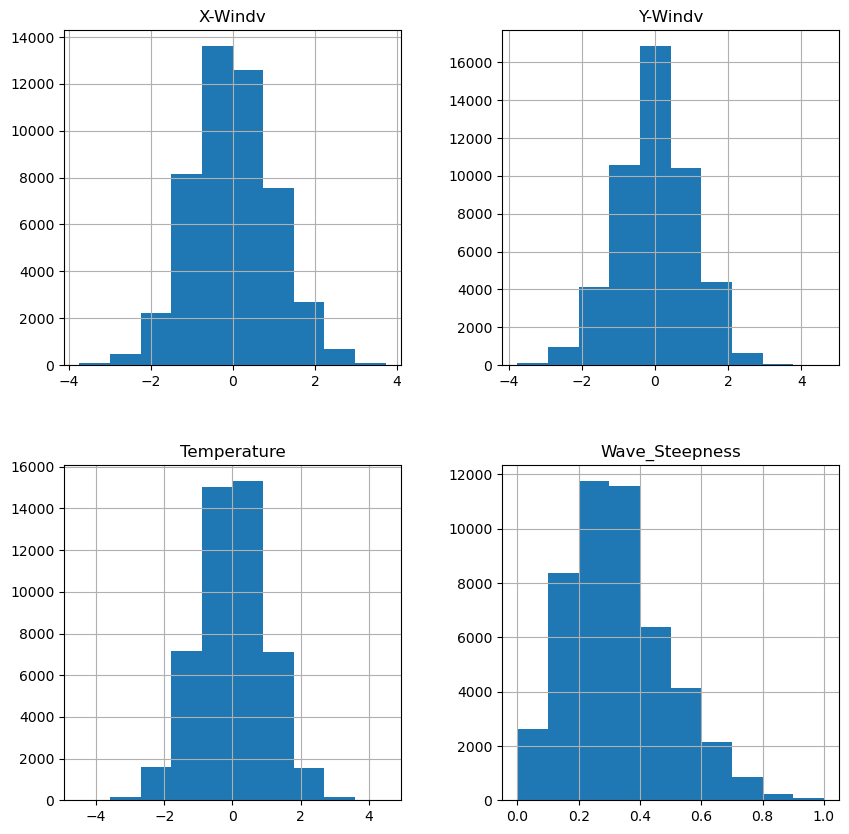

In [63]:
# Produce histograms for transformed numerical columns
X_train_prep_num = pd.DataFrame(num_tranformer.fit_transform(X_train[num_cols])
                                , columns=["X-Windv", "Y-Windv", "Temperature", "Wave_Steepness"])
X_train_prep_num.hist(figsize=(10, 10))
plt.show()

In [64]:
# Using parammetric models to predict the target feature using Linear Regression as the baseline model
from sklearn.linear_model import LinearRegression

# Creating the pipeline for the Linear Regression model
lr_pipe = Pipeline(steps=[
    ("preprocessor", prep_pipe),
    ("model", LinearRegression())
])

In [112]:
# Fitting the base model
lr_pipe.fit(X_train, y_train)

# Predicting the target feature
y_pred = lr_pipe.predict(X_test)

# Evaluating the model
from sklearn.metrics import mean_squared_error, r2_score

lr_r2 = r2_score(y_test, y_pred)
print(f"R2 Score: {lr_r2}")

lr_mse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"Root Mean Squared Error: {lr_mse}")

R2 Score: 0.8468962104042289
Root Mean Squared Error: 0.13271197072018642


In [120]:
# Using bagging and sequential models to predict the target feature using linear regression as the baseline model
from sklearn.ensemble import BaggingRegressor
from xgboost import XGBRegressor

# Creating the pipeline for the Bagging Regressor model
bagging_pipe = Pipeline(steps=[
    ("preprocessor", prep_pipe),
    ("model", BaggingRegressor(estimator=LinearRegression(), n_estimators=100))
])

# Creating the pipeline for the XGBoost Classifier model
xgb_pipe = Pipeline(steps=[
    ("preprocessor", prep_pipe),
    ("model", XGBRegressor())
])

In [121]:
# Using RandomizedSearchCV to tune the hyperparameters of the model
from sklearn.model_selection import RandomizedSearchCV

# Defining the hyperparameters for the models
param_distrib_bag = [
    {
        "model": [BaggingRegressor(estimator=LinearRegression())],
        "model__n_estimators": [10, 100, 1000],
        "model__max_samples": [0.33, 0.66, 1.0],
    },
]

param_distrib_xgb = [
    {
        "model": [XGBRegressor()],
        "model__n_estimators": [100, 200, 300, 400, 500],
        "model__learning_rate": [0.01, 0.1, 0.3, 0.5],
    }
]

In [122]:
# Creating the RandomizedSearchCV object
rand_search_bag = RandomizedSearchCV(
    estimator = lr_pipe,  # The model to tune
    param_distributions = param_distrib_bag,
    n_iter = 100,  # Run 100 different models
    scoring = {'r2': 'r2', 'neg_mean_squared_error': 'neg_mean_squared_error'},  # Score using R^2 and mean squared error
    refit = 'r2',  # Refit the model using the best score
    cv = 5,  # 5-fold cross-validation
    n_jobs = -1,  # Use all CPUs
    random_state = 42  # For reproducibility
)

rand_search_xgb = RandomizedSearchCV(
    estimator = lr_pipe,  # The model to tune
    param_distributions = param_distrib_xgb,
    n_iter = 100,  # Run 100 different models
    scoring = {'r2': 'r2', 'neg_mean_squared_error': 'neg_mean_squared_error'},  # Score using R^2 and mean squared error
    refit = 'r2',  # Refit the model using the best score
    cv = 5,  # 5-fold cross-validation
    n_jobs = -1,  # Use all CPUs
    random_state = 42  # For reproducibility
)

In [123]:
# Fitting the RandomizedSearchCV object to bagging model
rand_search_bag.fit(X_train, y_train)

/home/sp1720/miniconda3/envs/dsml2/lib/python3.8/site-packages/sklearn/model_selection/_search.py:307: UserWarning: The total space of parameters 9 is smaller than n_iter=100. Running 9 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               ColumnTransformer(transformers=[('std',
                                                                                                                Pipeline(steps=[('imputer',
                                                                                                                                 SimpleImputer(strategy='median')),
                                                                                                                                ('scaler',
                                                                                                                                 StandardScaler())]),
                                                                                                                ['X-Windv',
                                                                                                                 'Y-Windv',
                                                                                                                 'Temperature']),
                                                                                                               ('minmax',
                                                                                                                Pipeline(steps=[('imputer',
                                                                                                                                 SimpleImputer()),
                                                                                                                                ('scaler',
                                                                                                                                 MinMaxScaler()...
                                                                               Index(['Season', 'Wind_Dir_Category'], dtype='object'))])),
                                             ('model', LinearRegression())]),
                   n_iter=100, n_jobs=-1,
                   param_distributions=[{'model': [BaggingRegressor(estimator=LinearRegression())],
                                         'model__max_samples': [0.33, 0.66,
                                                                1.0],
                                         'model__n_estimators': [10, 100,
                                                                 1000]}],
                   random_state=42, refit='r2',
                   scoring={'neg_mean_squared_error': 'neg_mean_squared_error',
                            'r2': 'r2'})

In [124]:
# Fitting the RandomizedSearchCV object to xgb model
rand_search_xgb.fit(X_train, y_train)

/home/sp1720/miniconda3/envs/dsml2/lib/python3.8/site-packages/sklearn/model_selection/_search.py:307: UserWarning: The total space of parameters 20 is smaller than n_iter=100. Running 20 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               ColumnTransformer(transformers=[('std',
                                                                                                                Pipeline(steps=[('imputer',
                                                                                                                                 SimpleImputer(strategy='median')),
                                                                                                                                ('scaler',
                                                                                                                                 StandardScaler())]),
                                                                                                                ['X-Windv',
                                                                                                                 'Y-Windv',
                                                                                                                 'Temperature']),
                                                                                                               ('minmax',
                                                                                                                Pipeline(steps=[('imputer',
                                                                                                                                 SimpleImputer()),
                                                                                                                                ('scaler',
                                                                                                                                 MinMaxScaler()...
                                                                max_leaves=None,
                                                                min_child_weight=None,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=None,
                                                                n_jobs=None,
                                                                num_parallel_tree=None,
                                                                random_state=None, ...)],
                                         'model__learning_rate': [0.01, 0.1,
                                                                  0.3, 0.5],
                                         'model__n_estimators': [100, 200, 300,
                                                                 400, 500]}],
                   random_state=42, refit='r2',
                   scoring={'neg_mean_squared_error': 'neg_mean_squared_error',
                            'r2': 'r2'})

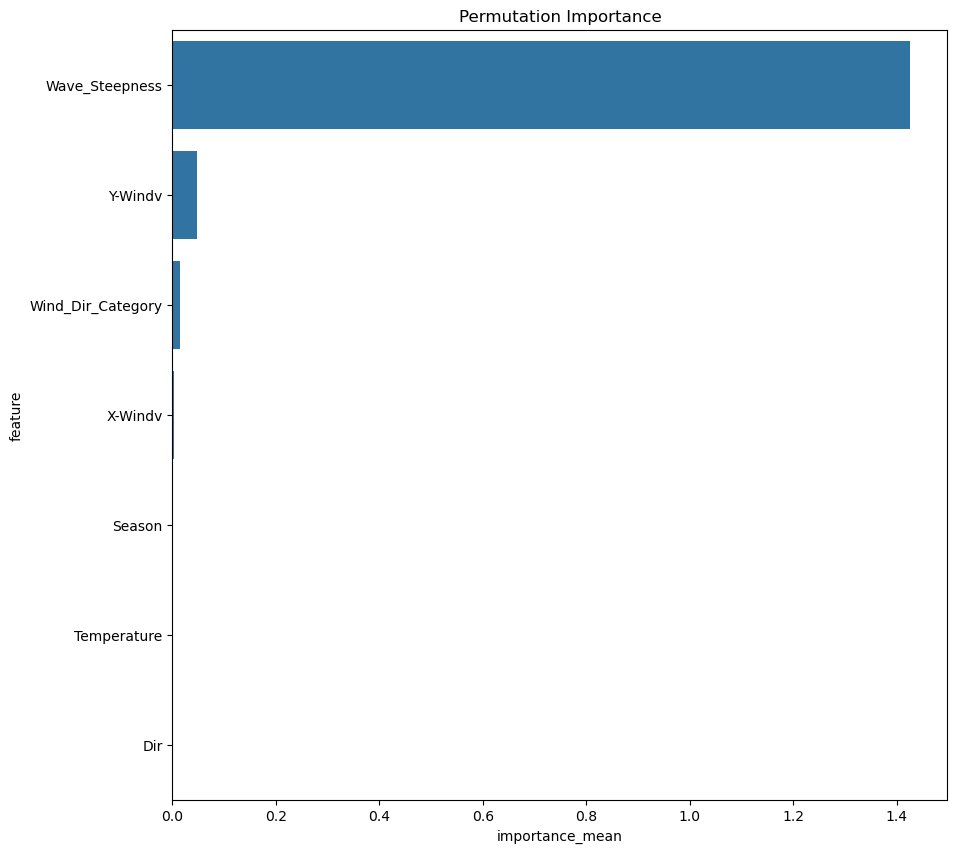

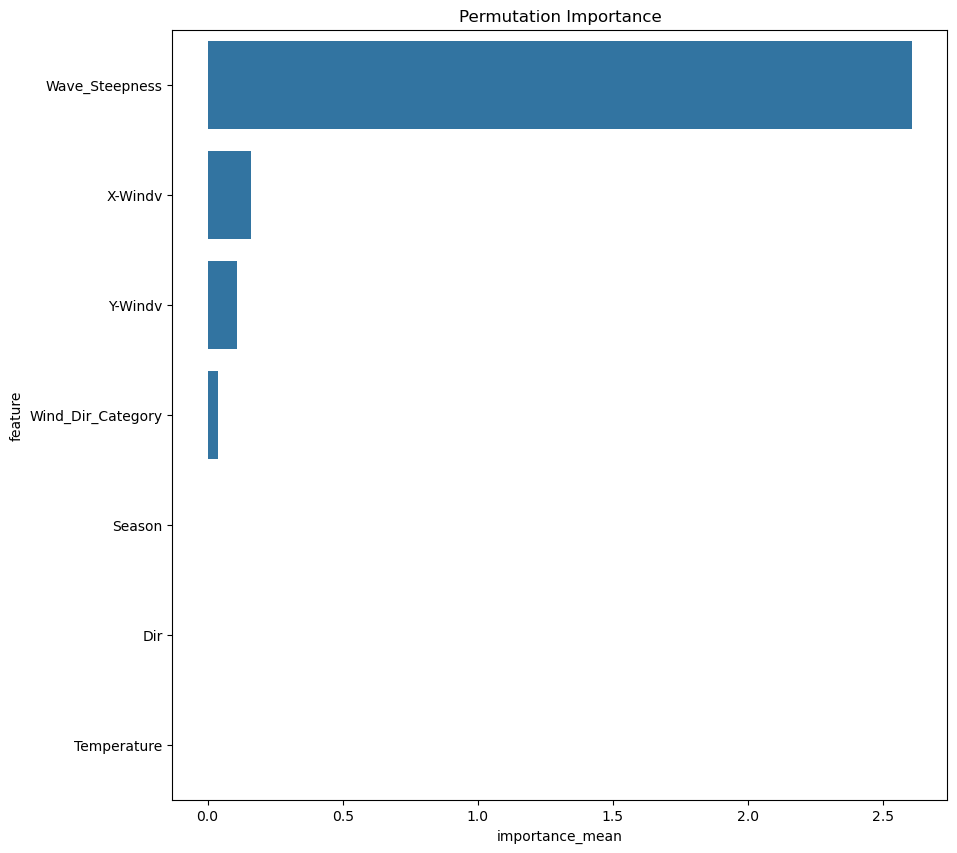

In [125]:
# Feature permutation
from sklearn.inspection import permutation_importance

def plot_permutation_importance(perm_importance, X_test):
    # Creating a DataFrame of the permutation importance
    perm_importance_df = pd.DataFrame(data={
        "feature": X_test.columns,
        "importance_mean": perm_importance["importances_mean"],
        "importance_std": perm_importance["importances_std"]
    })

    # Sorting the DataFrame by importance
    perm_importance_df = perm_importance_df.sort_values("importance_mean", ascending=False)

    # Plotting the permutation importance
    plt.figure(figsize=(10, 10))
    sns.barplot(data=perm_importance_df, x="importance_mean", y="feature")
    plt.title("Permutation Importance")
    plt.show()


# Getting the permutation importance
perm_importance_bag = permutation_importance(rand_search_bag, X_test, y_test, n_repeats=30, random_state=42)
perm_importance_xgb = permutation_importance(rand_search_xgb, X_test, y_test, n_repeats=30, random_state=42)

# Plotting the permutation importance
plot_permutation_importance(perm_importance_bag, X_test)
plot_permutation_importance(perm_importance_xgb, X_test)

The permutation importance shows that the most important feature by far is the wave steepness. 

This makes sense as wave steepness was much more highly correlated than the other features, once wind speed was dropped. 

To speed up the modelling, it may be better to drop Season, Dir and Temperature, as they are not meaningfully contributing to the final model output. However, the timescale to run the current models are under 5 minutes are therefore they will be kept in. 

In [126]:
def best_parameters(rand_search_prep):
    # Getting the best parameters and the best score
    # print(f"Best Model: {rand_search_prep.best_estimator_}")
    print(f"Best Parameters: {rand_search_prep.best_params_}")
    print(f"Best Score: {rand_search_prep.best_score_}")

    # R2 of best model:
    best_R2 = rand_search_prep.best_estimator_.score(X_test, y_test)

    # Mean Squared Error of best model:
    from sklearn.metrics import mean_squared_error
    best_mse = mean_squared_error(y_test, rand_search_prep.best_estimator_.predict(X_test))

    print(f"Best R2: {best_R2}")
    print(f"Best MSE: {best_mse}")

    # Saving the best model
    final_model = rand_search_prep.best_estimator_
    best_parameters = rand_search_prep.best_params_

    return final_model, best_parameters, best_R2, best_mse

In [127]:
# Getting the best parameters for the linear regression model
print("Linear Regression Model")
print(f"R2 Score: {lr_r2}")
print(f"Mean Squared Error: {lr_mse}")

# Getting the best parameters for the bagging model
print("\nBagging Model")
final_model_bag, best_parameters_bag, best_R2_bag, best_mse_bag = best_parameters(rand_search_bag)

# Getting the best parameters for the xgb model
print("\nXGB Model")
final_model_xgb, best_parameters_xgb, best_R2_xgb, best_mse_xgb = best_parameters(rand_search_xgb)

Linear Regression Model
R2 Score: 0.8468962104042289
Mean Squared Error: 0.13271197072018642

Bagging Model
Best Parameters: {'model__n_estimators': 100, 'model__max_samples': 0.33, 'model': BaggingRegressor(estimator=LinearRegression())}
Best Score: 0.8439478675674705
Best R2: 0.8468998344320173
Best MSE: 0.017612050278310237

XGB Model
Best Parameters: {'model__n_estimators': 200, 'model__learning_rate': 0.1, 'model': XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=No

In [128]:
# Final model is going to be the model with the best R2 score
final_model = final_model_xgb
best_R2 = best_R2_xgb
best_mse = best_mse_xgb

In [129]:
# Perform cross validation on the best model using r2 and mse as scoring metrics
from sklearn.model_selection import cross_val_score

# Cross validation using R^2
cv_r2 = cross_val_score(final_model, X_train, y_train, cv=5, scoring='r2')
cv_mse = cross_val_score(final_model, X_train, y_train, cv=5, scoring='neg_mean_squared_error')

print(f"Cross Validation R2: {cv_r2}")
print(f"Cross Validation MSE: {cv_mse}")

Cross Validation R2: [0.93937064 0.94292842 0.94523506 0.94105424 0.94234666]
Cross Validation MSE: [-0.00672276 -0.00667644 -0.00649772 -0.00682201 -0.00674076]


In [130]:
# Evaluating the model using the test set
final_model.score(X_test, y_test)

0.9440446037268667

In [131]:
# Plotting learning curve
from sklearn.model_selection import learning_curve
import numpy as np

def plot_learning_curve(estimator, X, y, cv=None, n_jobs=None, train_sizes=np.linspace(0.1, 1.0, 50), scoring=None, best_mse=None, best_R2=None):
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=cv, n_jobs=n_jobs, train_sizes=train_sizes, scoring=scoring)

    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    test_scores_std = np.std(test_scores, axis=1)

    plt.figure()
    plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, alpha=0.1, color="r")
    plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                     test_scores_mean + test_scores_std, alpha=0.1, color="g")

    plt.plot(train_sizes, train_scores_mean, '-', color="r", label="Training score")
    plt.plot(train_sizes, test_scores_mean, '-', color="g", label="Cross-validation score")

    # Adding RMSE and R2 for training and testing data to the plot
    plt.text(0.5, 0.5, f"Best RMSE: {round(np.sqrt(best_mse),6)}", fontsize=12, ha='left', va='baseline', transform=plt.gca().transAxes)
    plt.text(0.5, 0.45, f"Best R2: {round(best_R2,6)}", fontsize=12, ha='left', va='top', transform=plt.gca().transAxes)

    plt.xlabel("Training examples")
    plt.ylabel("RMS Error")
    plt.title(f"Learning Curve for {estimator.named_steps['model'].__class__.__name__}")
    plt.legend(loc="best")
    plt.show()


In [132]:
from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt

def plot_learning_curve(estimator, X, y, cv=None, n_jobs=None, train_sizes=np.linspace(0.1, 1.0, 50), scoring=None, best_mse=None, best_R2=None):
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=cv, n_jobs=n_jobs, train_sizes=train_sizes, scoring=scoring)

    train_scores_mean = np.mean(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)

    plt.figure()

    plt.plot(train_sizes, train_scores_mean, '-', color="r", label="Training score")
    plt.plot(train_sizes, test_scores_mean, '-', color="g", label="Cross-validation score")

    # Adding MSE and R2 for training and testing data to the plot
    plt.text(0.5, 0.5, f"Best RMSE: {round((best_mse),6)}", fontsize=12, ha='left', va='baseline', transform=plt.gca().transAxes)
    plt.text(0.5, 0.45, f"Best R2: {round(best_R2,6)}", fontsize=12, ha='left', va='top', transform=plt.gca().transAxes)

    plt.xlabel("Training examples")
    plt.ylabel("MS Error")
    plt.title(f"Learning Curve for {estimator.named_steps['model'].__class__.__name__}")
    plt.legend(loc="best")
    plt.show()

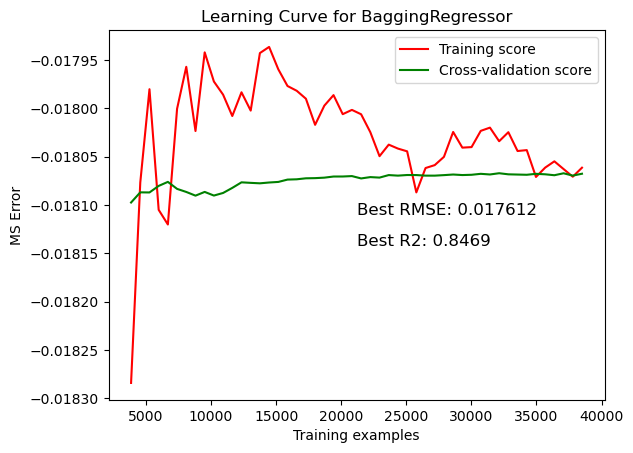

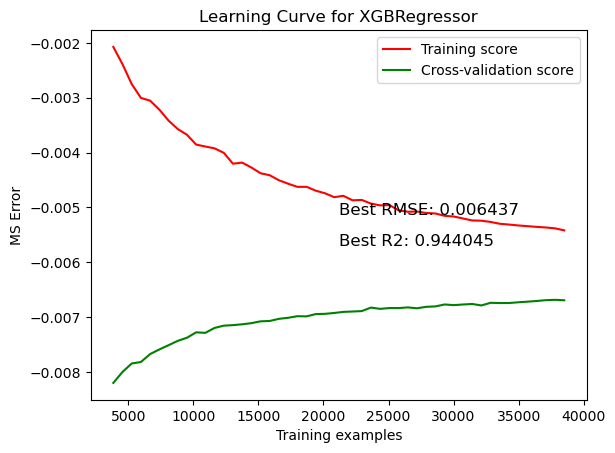

In [133]:
# Plotting the learning curve
plot_learning_curve(final_model_bag, X_train, y_train, cv=5, n_jobs=-1, scoring='neg_mean_squared_error', best_mse=best_mse_bag, best_R2=best_R2_bag)
plot_learning_curve(final_model_xgb, X_train, y_train, cv=5, n_jobs=-1, scoring='neg_mean_squared_error', best_mse=best_mse_xgb, best_R2=best_R2_xgb)



The lower RMSE and higher R2 score indicates that the XGB regressor outperforms the bagged regressor, where XGB steadily improves over time, but is contantly overfitting the training data. At the max iteration of training examples of 40,000, the MSE score was 

For the bagging regressor, it similarly overfits the data on average, and reduces in MSE as the number of training points increases. At the max iteration of training examples of 40,000, the MSE score was 

Therefore, of the methods analysed, XGB regressor would be best to use, given the best parameters stated. 

To get conduct meaningful hyperparameter tuning further, other criteria Max error, MAE, or MSE could be used. Or other hyperparameters could be tuned to achieve a better score for the model. 